First the relevant libraries are imported into the notebook

In [1]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem import PandasTools

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_palette("husl")

from data_profiling import ProfileReport   

Converting the data set SDF file into a CSV using https://stackoverflow.com/questions/78004477/convert-simple-data-format-file-sdf-to-csv

In [3]:
def sdf_to_csv(sdf_file, output_csv_file, delimiter=','):
    """
    Convert an SDF file to a CSV or TSV file.
    
    Args:
        sdf_file (str): Path to the input SDF file.
        output_file (str): Path to the output CSV or TSV file.
        delimiter (str, optional): Delimiter to use in the output file. Default is ',' (CSV).
    """
    # Read the SDF file
    suppl = Chem.SDMolSupplier(sdf_file)

    # Convert to a pandas DataFrame
    df = PandasTools.LoadSDF(sdf_file, smilesName='SMILES', molColName='Molecule', includeFingerprints=False)

    # Drop the 'Molecule' column if present
    if 'Molecule' in df.columns:
        df = df.drop('Molecule', axis=1)

    # Save the DataFrame as CSV or TSV
    df.to_csv(output_csv_file, sep=delimiter, index=False)
    
    print(f"Conversion complete! Output file: {output_csv_file}")

Running the Conversion, and initializing the data set as df for further EDA, saving it as a CSV for easier reference

In [ ]:
sdf_file = "tox21_10k_data_all.sdf"  # Replace with your SDF file path
output_csv_file = "tox21_10k_data_all.csv"  # Output CSV file

sdf_to_csv(sdf_file, output_csv_file, delimiter=',')  # Use ',' for CSV

In [21]:
df = pd.read_csv(output_csv_file)
df

,Formula,FW,DSSTox_CID,SR-HSE,ID,SMILES,NR-AR,SR-ARE,NR-Aromatase,NR-ER-LBD,NR-AhR,SR-MMP,NR-ER,NR-PPAR-gamma,SR-p53,SR-ATAD5,NR-AR-LBD
0,C27H25ClN6,468.9806 (35.4535+224.2805+209.2465),25848,0.0,NCGC00178831-03,C[n+]1c2cc(N)ccc2cc2ccc(N)cc21.Nc1ccc2cc3ccc(N...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C20H6Br4Na2O5,691.8542 (645.8757+22.9892+22.9892),5234,0.0,NCGC00166114-03,O=C([O-])c1ccccc1-c1c2cc(Br)c(=O)c(Br)c-2oc2c(...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C47H83NO17,934.1584 (916.1205+18.0379),28909,0.0,NCGC00263563-01,CO[C@@H]1[C@@H](OC)[C@H](C)[C@@](O)(CC(=O)[O-]...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C52H54N4O12,927.0048 (329.4575+89.0275+89.0275+329.4575+90...,5513,1.0,NCGC00013058-02,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)c...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C66H87N17O14,1342.5025 (1282.4505+60.0520),26683,NaN,NCGC00167516-01,CC(=O)O.CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(=...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11756,C7H10N2OS,170.2321,1209,0.0,NCGC00259290-01,CCCc1cc(=O)[nH]c(=S)[nH]1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11757,C3H6N2S,102.1581,601,0.0,NCGC00258846-01,S=C1NCCN1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11758,C3H6N2S,102.1581,601,0.0,NCGC00254936-01,S=C1NCCN1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11759,C10H14NO5PS,291.2606,1100,0.0,NCGC00254571-01,CCOP(=S)(OCC)Oc1ccc([N+](=O)[O-])cc1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


**The above does not need to be run again, aside from importing relevant libraries**

**Loading local versions**

In [2]:
df = pd.read_csv("data/raw_data_tox21.csv")
df

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7826,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX2725,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...
7827,1.0,1.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,TOX2370,CC(=O)[C@H]1CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(...
7828,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX2371,C[C@]12CC[C@H]3[C@@H](CCC4=CC(=O)CC[C@@]43C)[C...
7829,1.0,1.0,0.0,NaN,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,TOX2377,C[C@]12CC[C@@H]3c4ccc(O)cc4CC[C@H]3[C@@H]1CC[C...


Verifying the data set was successfully loaded

Next a sub data set is taken from the overall data set focusing on key characteristics for this project, including the formula, formula weight, ID, smiles, mol object, and the 5 stress response indicators.

In [3]:
df_of_study = df[['mol_id','smiles', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']]
df_of_study.head()

,mol_id,smiles,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,1.0,0.0,0.0,0.0,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,NaN,0.0,NaN,0.0,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,0.0,NaN,0.0,NaN,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,NaN,0.0,NaN,0.0,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0,0.0,0.0,0.0,0.0


The dataset is checked for duplicate molecules

In [4]:
unique_molecules = df_of_study['mol_id'].nunique()
num_molecules = df_of_study['mol_id'].shape[0]
print(f'Unique molecules: {unique_molecules}')
print(f'Total molecules: {num_molecules}')

Unique molecules: 7831
Total molecules: 7831


No repeating molecule IDs were found. Next we ensure each smiles value is unique

In [5]:
unique_smiles = df_of_study['smiles'].nunique()
num_smiles = df_of_study['smiles'].shape[0]
print(f'Unique SMILES: {unique_smiles}')
print(f'Total SMILES: {num_smiles}')

Unique SMILES: 7831
Total SMILES: 7831


The functions below are declared for adding the mol objects  and cononicalizing isomeric SMILES

In [ ]:
def add_mol_object(smile, isomeric:bool=True):
    mol = Chem.MolFromSmiles(smile)
    return mol

def canonicalize_smiles(smiles, isomeric=True):
    if not isinstance(smiles, str) or not smiles.strip():
        return None

    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return Chem.MolToSmiles(mol, isomericSmiles=isomeric)



df_of_study['mol'] = df_of_study['smiles'].apply(add_mol_object)
df_of_study['canon_smiles'] = df_of_study['smiles'].apply(canonicalize_smiles)

The mol objects and canon smile format of molecules are added to the dataframe in new columns

Seeing what has changed

In [13]:
changed = df_of_study[df_of_study['smiles'] != df_of_study['canon_smiles']]

print(f"Total changed: {len(changed)}")


Total changed: 316


The function successfully canonicalized the smiles of some molecules

A function is defined to apply ALL key molecular descriptors to the dataset, it is then run to find and assign these values to the respective molecules.

In [ ]:
def calculate_desc(mol):
    description = Descriptors.CalcMolDescriptors(mol, missingVal=None, silent=True)
    return description


descriptors_data = []
for row, smiles in df_of_study['canon_smiles'].items():
    mol = Chem.MolFromSmiles(str(smiles))
    desc = calculate_desc(mol)
    descriptors_data.append(desc)

descriptors_df = pd.DataFrame(descriptors_data)

df_with_descriptors = pd.concat([df_of_study, descriptors_df], axis=1)

df_with_descriptors.head()


This was the original version used to test the process using a choice of 6 molecular descriptors

def calculate_key_descriptors(mol):
    descriptors = {
        'MolWt': Descriptors.MolWt(mol),
        'LogP' : Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'RotBonds' : Descriptors.NumRotatableBonds(mol)
    }
    return descriptors

descriptor_data = []
for row, mol in df['molecule'].items():
    if mol is None:
        desc = {
            'MolWt': np.nan,
            'LogP': np.nan,
            'TPSA': np.nan,
            'NumHDonors': np.nan,
            'NumHAcceptors': np.nan,
            'RotBonds': np.nan
        }
    else:
        desc = calculate_key_descriptors(mol)
    descriptor_data.append(desc)

descriptor_df = pd.DataFrame(descriptor_data, index=df.index)

df_with_descriptors = pd.concat([df, descriptor_df], axis=1)

df_with_descriptors.head()

Information about the dataset with descriptors is checked

In [16]:
df_with_descriptors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7831 entries, 0 to 7830
Columns: 226 entries, mol_id to fr_urea
dtypes: float64(222), object(4)
memory usage: 13.5+ MB


In [17]:
df_with_descriptors.describe()

c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in su

,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
count,5832.000000,7072.000000,6467.000000,5810.000000,6774.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,...,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000,7823.000000
mean,0.161523,0.037330,0.057523,0.158003,0.062445,9.829003,9.829003,0.342054,-0.825121,0.545283,...,0.040394,0.036942,0.007798,0.005752,0.004091,0.015212,0.001662,0.012016,0.598875,0.028506
std,0.368044,0.189583,0.232857,0.364776,0.241979,3.142115,3.142115,0.495326,1.590247,0.189256,...,0.229291,0.216998,0.092221,0.075630,0.065803,0.134352,0.043760,0.121184,2.284688,0.179719
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-9.769375,0.010404,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,8.557450,8.557450,0.067544,-1.200521,0.425364,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,10.662037,10.662037,0.184583,-0.432528,0.549929,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,12.007481,12.007481,0.427039,0.139028,0.686685,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,17.442653,17.442653,8.764932,4.000000,0.944994,...,4.000000,2.000000,2.000000,1.000000,2.000000,4.000000,2.000000,3.000000,36.000000,4.000000


Next the correlations between the key descriptors are evaluated by creating a list of all descriptor column names, and using that to test the correlation within the data frame

In [36]:
descriptor_columns = df_with_descriptors.columns[9:]
correlation_matrix = df_with_descriptors[descriptor_columns].corr().abs()

correlation_matrix

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
MaxAbsEStateIndex,1.000000,1.000000,0.436860,0.491279,0.000262,0.219866,0.448037,0.452521,0.448475,0.471627,...,0.043185,0.124887,0.061885,0.021767,0.031768,0.000237,0.013204,0.000970,0.070459,0.101314
MaxEStateIndex,1.000000,1.000000,0.436860,0.491279,0.000262,0.219866,0.448037,0.452521,0.448475,0.471627,...,0.043185,0.124887,0.061885,0.021767,0.031768,0.000237,0.013204,0.000970,0.070459,0.101314
MinAbsEStateIndex,0.436860,0.436860,1.000000,0.000097,0.082050,0.108365,0.194663,0.190443,0.194710,0.213739,...,0.028717,0.049548,0.033941,0.019774,0.020671,0.004522,0.021815,0.005553,0.062992,0.035673
MinEStateIndex,0.491279,0.491279,0.000097,1.000000,0.103787,0.093491,0.355042,0.371508,0.355138,0.321982,...,0.004639,0.372621,0.145662,0.007403,0.004504,0.001550,0.028690,0.013547,0.042336,0.071633
qed,0.000262,0.000262,0.082050,0.103787,1.000000,0.037138,0.326225,0.318387,0.326423,0.328506,...,0.064045,0.085916,0.041551,0.008870,0.050166,0.033876,0.030236,0.048844,0.318310,0.023940
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fr_thiazole,0.000237,0.000237,0.004522,0.001550,0.033876,0.018922,0.094768,0.099186,0.094802,0.082614,...,0.150203,0.007033,0.009574,0.008613,0.079726,1.000000,0.017445,0.004477,0.028849,0.008513
fr_thiocyan,0.013204,0.013204,0.021815,0.028690,0.030236,0.021428,0.023334,0.022401,0.023320,0.026067,...,0.171691,0.006466,0.003211,0.002889,0.002361,0.017445,1.000000,0.003766,0.002832,0.006024
fr_thiophene,0.000970,0.000970,0.005553,0.013547,0.048844,0.004148,0.044941,0.047712,0.044861,0.031631,...,0.014737,0.046319,0.014494,0.007542,0.025900,0.004477,0.003766,1.000000,0.025071,0.001881
fr_unbrch_alkane,0.070459,0.070459,0.062992,0.042336,0.318310,0.093051,0.092616,0.066792,0.092835,0.142163,...,0.018851,0.001012,0.011244,0.015500,0.009494,0.028849,0.002832,0.025071,1.000000,0.036911


And plotted in a heatmap for convenient visual representation

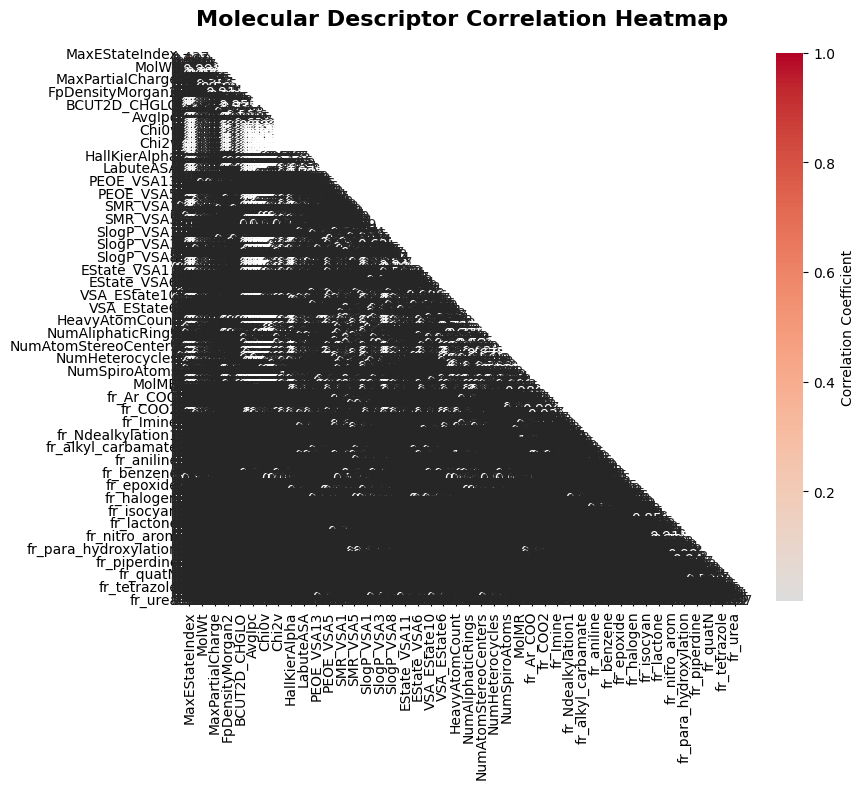

In [19]:
plt.figure(figsize=(10, 8))

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True,cmap='coolwarm', center=0, square=True,fmt='.3f',cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Molecular Descriptor Correlation Heatmap', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

This is not a useful representaiton, so removing some highly correlated descriptors, or descriptors that show no variance across the data set becomes the next step

In [20]:
feature_variance = df_with_descriptors[descriptor_columns].var()
redundant_features = feature_variance[feature_variance == 0].index.tolist()
print(f"Redundant features (zero variance): {redundant_features}")

Redundant features (zero variance): ['SMR_VSA8', 'SlogP_VSA9', 'fr_diazo']


c:\Users\brand\Documents\University of Toronto\2. Courses\CHE1147 Chemical Data Science and Engineering\CHE1147\.venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


Removing the redundant features

In [21]:
print(f"Number of features before: {len(descriptor_columns)}")
descriptor_columns = [descriptor for descriptor in descriptor_columns if descriptor not in redundant_features]
print(f"Number of features after: {len(descriptor_columns)}")

Number of features before: 216
Number of features after: 213


Next the highly correlated descriptors are addressed, first by updating the correlation matrix with the updated descriptors, and declaring a function to sift through the correlation matrix and remove the highly correlated descriptors

In [37]:
descriptor_columns = df_with_descriptors.columns[9:]

correlation_matrix = df_with_descriptors[descriptor_columns].corr()

def remove_highly_correlated_descriptors(correlation_matrix, threshold=0.90):
    #avoids redundancy by only searching the upper triangle of the correlation matrix to avoid being redundant and avoids the diagonal of self correlation
    top_of_corr_matrix = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    descriptors_to_remove = [column for column in top_of_corr_matrix.columns if any(top_of_corr_matrix[column].abs() > threshold)]

    reduced_descriptors_matrix = correlation_matrix.drop(descriptors_to_remove, axis=1)

    return reduced_descriptors_matrix

test_reduced_correlation_matrix = remove_highly_correlated_descriptors(correlation_matrix, 0.9)

test_reduced_correlation_matrix

,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,NumRadicalElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
MaxAbsEStateIndex,1.000000,-0.436860,-0.491279,0.000262,0.219866,0.448037,-0.058492,0.340331,-0.424952,0.250082,...,0.043185,0.124887,0.061885,0.021767,0.031768,0.000237,-0.013204,-0.000970,-0.070459,0.101314
MaxEStateIndex,1.000000,-0.436860,-0.491279,0.000262,0.219866,0.448037,-0.058492,0.340331,-0.424952,0.250082,...,0.043185,0.124887,0.061885,0.021767,0.031768,0.000237,-0.013204,-0.000970,-0.070459,0.101314
MinAbsEStateIndex,-0.436860,1.000000,-0.000097,-0.082050,-0.108365,-0.194663,-0.027173,-0.178081,0.204270,-0.195264,...,-0.028717,-0.049548,-0.033941,-0.019774,-0.020671,-0.004522,0.021815,0.005553,0.062992,-0.035673
MinEStateIndex,-0.491279,-0.000097,1.000000,0.103787,-0.093491,-0.355042,0.010495,-0.396892,0.273524,-0.309755,...,-0.004639,-0.372621,-0.145662,0.007403,-0.004504,-0.001550,0.028690,0.013547,0.042336,-0.071633
qed,0.000262,-0.082050,0.103787,1.000000,-0.037138,-0.326225,-0.039508,-0.097493,-0.001743,-0.082112,...,-0.064045,0.085916,0.041551,0.008870,-0.050166,-0.033876,-0.030236,0.048844,-0.318310,0.023940
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fr_thiazole,0.000237,-0.004522,-0.001550,-0.033876,-0.018922,0.094768,-0.004963,0.021011,-0.008277,-0.002983,...,0.150203,0.007033,-0.009574,-0.008613,0.079726,1.000000,0.017445,0.004477,-0.028849,0.008513
fr_thiocyan,-0.013204,0.021815,0.028690,-0.030236,-0.021428,-0.023334,-0.001665,-0.015220,0.008146,-0.011367,...,0.171691,-0.006466,-0.003211,-0.002889,-0.002361,0.017445,1.000000,-0.003766,0.002832,-0.006024
fr_thiophene,-0.000970,0.005553,0.013547,0.048844,0.004148,0.044941,-0.004346,-0.007972,0.016362,-0.025761,...,0.014737,0.046319,0.014494,-0.007542,0.025900,0.004477,-0.003766,1.000000,-0.025071,0.001881
fr_unbrch_alkane,-0.070459,0.062992,0.042336,-0.318310,-0.093051,0.092616,-0.011490,-0.032972,0.001252,-0.014566,...,-0.018851,0.001012,-0.011244,-0.015500,-0.009494,-0.028849,0.002832,-0.025071,1.000000,-0.036911


The reduced descriptors are added to the data set of study

In [40]:
core_cols = df_with_descriptors.iloc[:, :9]
descr_cols = test_reduced_correlation_matrix.columns
simplified_df = pd.concat([core_cols, df_with_descriptors[descr_cols]],axis=1)
simplified_df


,mol_id,smiles,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol,canon_smiles,MaxAbsEStateIndex,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,1.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193B8F...,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,11.107593,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,NaN,0.0,NaN,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193B8F...,CCN1C(=O)NC(c2ccccc2)C1=O,11.790004,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,0.0,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000193B8F...,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,11.165775,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,NaN,0.0,NaN,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193B8F...,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,12.570517,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193843...,CC(O)(P(=O)(O)O)P(=O)(O)O,10.251875,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7826,TOX2725,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,0.0,NaN,0.0,NaN,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000193845...,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,11.819107,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7827,TOX2370,CC(=O)[C@H]1CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(...,NaN,0.0,0.0,NaN,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193845...,CC(=O)[C@H]1CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(...,12.146718,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7828,TOX2371,C[C@]12CC[C@H]3[C@@H](CCC4=CC(=O)CC[C@@]43C)[C...,1.0,0.0,0.0,0.0,0.0,<rdkit.Chem.rdchem.Mol object at 0x00000193845...,C[C@]12CC[C@H]3[C@@H](CCC4=CC(=O)CC[C@@]43C)[C...,11.787348,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7829,TOX2377,C[C@]12CC[C@@H]3c4ccc(O)cc4CC[C@H]3[C@@H]1CC[C...,0.0,0.0,0.0,1.0,1.0,<rdkit.Chem.rdchem.Mol object at 0x00000193845...,C[C@]12CC[C@@H]3c4ccc(O)cc4CC[C@H]3[C@@H]1CC[C...,10.372487,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Since there are still a significant number of molecular descriptors, we can also remove all features that have low relevance to the data set. For example, all descriptors with an average value of 0 will be removed

In [ ]:
descriptor_means = simplified_df.iloc[:, 9:].mean()
zero_mean_columns = descriptor_means[descriptor_means == 0].index.tolist()

print("Descriptor means:")
display(descriptor_means)
print(f"Removing {len(zero_mean_columns)} zero-mean columns: {zero_mean_columns}")

simplified_df_v2 = simplified_df.drop(columns=zero_mean_columns)
simplified_df_v2.head()

In [ ]:
variance_threshold = 1e-4  # Adjust to control how aggressively features are removed

descriptor_cols = simplified_df_v2.columns[9:]
descriptor_variance = simplified_df_v2[descriptor_cols].var()

low_variance_cols = descriptor_variance[
    descriptor_variance < variance_threshold
].index.tolist()

print(f"Removing {len(low_variance_cols)} low-variance descriptors:")
print(low_variance_cols)

simplified_df_v3 = simplified_df_v2.drop(columns=low_variance_cols)
simplified_df_v3.shape

Next the key features for comparison are plotted. **NEEDS TO BE FIXED**

fig, axes = plt.subplots(217, 176, figsize=(15, 10))
fig.suptitle('Distribution of Key Molecular Descriptors', fontsize=16, fontweight='bold')


for i, descriptor in enumerate(descriptor_columns):
    row = i // 3
    col = i % 3

    axes[row, col].hist(test_reduced_correlation_matrix[descriptor].dropna(), bins=30, color='skyblue', edgecolor='black')

    mean_val = df_with_descriptors[descriptor].mean()
    median_val = df_with_descriptors[descriptor].median()
    axes[row, col].axvline(mean_val, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
    axes[row, col].axvline(median_val, color='green', linestyle='dashed', linewidth=1, label=f'Median: {median_val:.2f}')
    axes[row, col].set_title(f'{descriptor} Distribution', fontsize=14)
    axes[row, col].set_xlabel(descriptor, fontsize=12)
    axes[row, col].set_ylabel('Density', fontsize=12)
    axes[row, col].legend()
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Using the ProfileReport feature from data_profilling (previously ydata-profiling) a complete EDA report is generated and then displayed inline with the Jupyter Notebook

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 228/228 [00:05<00:00, 39.11it/s]


MemoryError: bad allocation

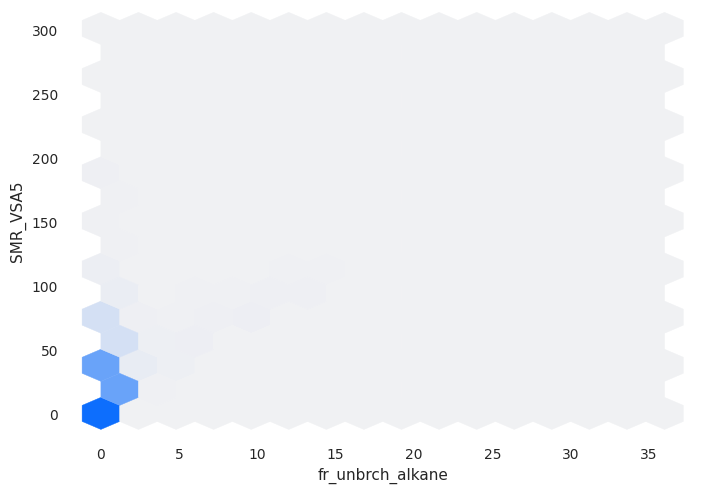

In [76]:
profile = ProfileReport(df_with_descriptors, title="Tox21 Dataset EDA Report - 0 Var Removed", explorative=True)
profile

Finally the EDA report for the Tox 21 data set is exported into an html file for easy viewing and sharing

In [ ]:
profile.to_file("tox21_eda_report_0_var_removed.html")